In [ ]:
import pandas as pd

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

# Load datasets from your Google Drive Sales_Data folder
customers = pd.read_csv('/content/drive/My Drive/Sales_Data/customers.csv')
orders = pd.read_csv('/content/drive/My Drive/Sales_Data/orders.csv')
order_item = pd.read_csv('/content/drive/My Drive/Sales_Data/order_item.csv')
products = pd.read_csv('/content/drive/My Drive/Sales_Data/products.csv')

print("All files loaded successfully from Google Drive!")

All files loaded successfully from Google Drive!


In [ ]:
print(customers.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   customer_id          3600 non-null   int64 
 1   signup_date          3600 non-null   object
 2   state                3600 non-null   object
 3   acquisition_channel  3600 non-null   object
dtypes: int64(1), object(3)
memory usage: 112.6+ KB
None


In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9207 entries, 0 to 9206
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        9207 non-null   int64  
 1   customer_id     9207 non-null   int64  
 2   order_date      9207 non-null   object 
 3   status          9207 non-null   object 
 4   payment_method  9207 non-null   object 
 5   discount_code   1405 non-null   object 
 6   shipping_fee    9207 non-null   float64
dtypes: float64(1), int64(2), object(4)
memory usage: 503.6+ KB


In [ ]:
print("CUSTOMERS MISSING VALUES:")
print(customers.isnull().sum())

CUSTOMERS MISSING VALUES:
customer_id            0
signup_date            0
state                  0
acquisition_channel    0
dtype: int64


In [ ]:
orders.isnull().sum()

,0
order_id,0
customer_id,0
order_date,0
status,0
payment_method,0
discount_code,7802
shipping_fee,0


In [ ]:
order_item.isnull().sum()

,0
order_id,0
product_id,0
quantity,0
unit_price_new,0
discount_amount,0


In [ ]:
products.isnull().sum()

,0
product_id,0
product_name,0
category_new,0
list_price,0
unit_cost,0


In [ ]:
orders['discount_code']=orders['discount_code'].fillna('no discount')

In [ ]:
orders

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
0,100001,1530,01/01/2024,completed,credit_card,no discount,6.95
1,100002,3531,01/01/2024,completed,credit_card,no discount,0.00
2,100003,840,01/01/2024,completed,credit_card,no discount,0.00
3,100004,725,01/01/2024,completed,apple_pay,WELCOME10,0.00
4,100005,3452,01/01/2024,completed,gift_card,no discount,0.00
...,...,...,...,...,...,...,...
9202,109203,3499,31/12/2025,completed,credit_card,HOLIDAY20,6.95
9203,109204,3410,31/12/2025,completed,credit_card,HOLIDAY20,0.00
9204,109205,2911,31/12/2025,completed,credit_card,no discount,0.00
9205,109206,1157,31/12/2025,completed,credit_card,no discount,6.95


In [ ]:
customers['signup_date']

,signup_date
0,13/09/2024
1,21/10/2025
2,17/01/2025
3,23/06/2024
4,08/04/2025
...,...
3595,14/11/2025
3596,27/05/2025
3597,03/06/2024
3598,23/08/2025


In [ ]:
customers['signup_date']=pd.to_datetime(customers['signup_date'],format='%d/%m/%Y')

In [ ]:
customers.duplicated().sum()


np.int64(0)

In [ ]:
customers['customer_id'].duplicated().sum()

np.int64(0)

In [ ]:
item_product_merged= pd.merge(order_item , products , on='product_id' , how='left')
print(item_product_merged.head())

   order_id  product_id  quantity  unit_price_new  discount_amount  \
0    100001        1031         1           38.99              0.0   
1    100002        1087         1           45.99              0.0   
2    100002        1072         1          141.99              0.0   
3    100003        1048         1          139.99              0.0   
4    100004        1083         1           19.99              2.0   

                  product_name category_new  list_price  unit_cost  
0     Stoneware Soap Dispenser         Bath       38.99      20.19  
1  Cotton Pantry Container Set      Storage       45.99      20.30  
2    Coastal Picture Frame Set        Decor      141.99      62.78  
3               Linen Loveseat    Furniture      139.99      71.41  
4      Velvet Drawer Organizer      Storage       19.99       9.51  


In [ ]:
full_sales_data=pd.merge(item_product_merged,orders,on='order_id',how='left')
print(full_sales_data.head())

   order_id  product_id  quantity  unit_price_new  discount_amount  \
0    100001        1031         1           38.99              0.0   
1    100002        1087         1           45.99              0.0   
2    100002        1072         1          141.99              0.0   
3    100003        1048         1          139.99              0.0   
4    100004        1083         1           19.99              2.0   

                  product_name category_new  list_price  unit_cost  \
0     Stoneware Soap Dispenser         Bath       38.99      20.19   
1  Cotton Pantry Container Set      Storage       45.99      20.30   
2    Coastal Picture Frame Set        Decor      141.99      62.78   
3               Linen Loveseat    Furniture      139.99      71.41   
4      Velvet Drawer Organizer      Storage       19.99       9.51   

   customer_id  order_date     status payment_method discount_code  \
0         1530  01/01/2024  completed    credit_card   no discount   
1         3531  01

In [ ]:
full_sales_data['total_revenue'] = full_sales_data['quantity'] * full_sales_data['unit_price_new']-full_sales_data['discount_amount']
print(full_sales_data[['order_id', 'product_name', 'quantity', 'unit_price_new', 'discount_amount', 'total_revenue']].head())

   order_id                 product_name  quantity  unit_price_new  \
0    100001     Stoneware Soap Dispenser         1           38.99   
1    100002  Cotton Pantry Container Set         1           45.99   
2    100002    Coastal Picture Frame Set         1          141.99   
3    100003               Linen Loveseat         1          139.99   
4    100004      Velvet Drawer Organizer         1           19.99   

   discount_amount  total_revenue  
0              0.0          38.99  
1              0.0          45.99  
2              0.0         141.99  
3              0.0         139.99  
4              2.0          17.99  


In [ ]:
# Check all column names in the customers table
print("Customer columns:", customers.columns.tolist())

Customer columns: ['customer_id', 'signup_date', 'state', 'acquisition_channel']


Which marketing channel actually brings in the best customers?

In [ ]:
complete_business_data = pd.merge(
    full_sales_data,
    customers[['customer_id', 'signup_date', 'acquisition_channel']],
    on='customer_id',
    how='left'
)
print(complete_business_data.head())

   order_id  product_id  quantity  unit_price_new  discount_amount  \
0    100001        1031         1           38.99              0.0   
1    100002        1087         1           45.99              0.0   
2    100002        1072         1          141.99              0.0   
3    100003        1048         1          139.99              0.0   
4    100004        1083         1           19.99              2.0   

                  product_name category_new  list_price  unit_cost  \
0     Stoneware Soap Dispenser         Bath       38.99      20.19   
1  Cotton Pantry Container Set      Storage       45.99      20.30   
2    Coastal Picture Frame Set        Decor      141.99      62.78   
3               Linen Loveseat    Furniture      139.99      71.41   
4      Velvet Drawer Organizer      Storage       19.99       9.51   

   customer_id  order_date     status payment_method discount_code  \
0         1530  01/01/2024  completed    credit_card   no discount   
1         3531  01

In [ ]:
channel_performance = complete_business_data.groupby('acquisition_channel')['total_revenue'].agg(['sum', 'count','mean']).reset_index()
print(channel_performance)

  acquisition_channel        sum  count        mean
0           affiliate   68351.40    542  126.109594
1               email  279594.06   2131  131.203219
2      organic_search  845002.67   6327  133.555029
3         paid_search  320742.25   2391  134.145650
4         paid_social  259406.67   1911  135.743940
5            referral  300899.53   2306  130.485486


In [ ]:
print(complete_business_data.sort_values(by='total_revenue', ascending=False))

       order_id  product_id  quantity  unit_price_new  discount_amount  \
3156     101818        1059         4          467.99             0.00   
12794    107526        1059         4          491.39           196.56   
11877    106960        1059         3          491.39             0.00   
10968    106417        1059         3          491.39             0.00   
11479    106728        1059         3          491.39             0.00   
...         ...         ...       ...             ...              ...   
5858     103410        1030         1            7.99             1.60   
6139     103578        1030         1            7.99             1.60   
6482     103782        1030         1            7.99             1.60   
7046     104112        1030         1            7.99             1.60   
5914     103443        1030         1            7.99             1.60   

                     product_name category_new  list_price  unit_cost  \
3156           Cotton Patio Chair     

In [ ]:
# Group by discount code to compare performance metrics
discount_analysis = complete_business_data.groupby('discount_code').agg(
    total_orders=('order_id', 'count'),
    total_revenue=('total_revenue', 'sum'),
    average_order_value=('total_revenue', 'mean'),
    avg_quantity=('quantity', 'mean')
).reset_index()

print(discount_analysis)


  discount_code  total_orders  total_revenue  average_order_value  \
0     HOLIDAY20          1327      133236.25           100.404107   
1      SPRING15           408       43401.99           106.377426   
2     WELCOME10           643       80643.35           125.417341   
3   no discount         13230     1816714.99           137.317837   

   avg_quantity  
0      1.252449  
1      1.240196  
2      1.213064  
3      1.245729  


In [ ]:
print(discount_analysis.sort_values(by='total_revenue', ascending=False))

  discount_code  total_orders  total_revenue  average_order_value  \
3   no discount         13230     1816714.99           137.317837   
0     HOLIDAY20          1327      133236.25           100.404107   
2     WELCOME10           643       80643.35           125.417341   
1      SPRING15           408       43401.99           106.377426   

   avg_quantity  
3      1.245729  
0      1.252449  
2      1.213064  
1      1.240196  


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
channel_revenue = complete_business_data.groupby('acquisition_channel')['total_revenue'].sum().reset_index()
channel_revenue = channel_revenue.sort_values(by='total_revenue', ascending=False)

/tmp/ipykernel_2902/1841069080.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


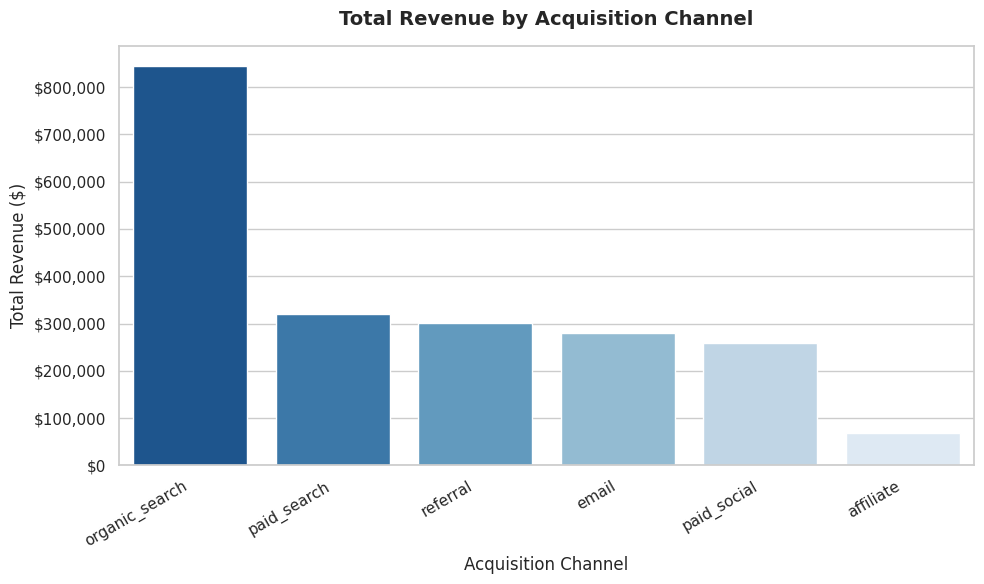

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare the data
channel_revenue = complete_business_data.groupby('acquisition_channel')['total_revenue'].sum().reset_index()
channel_revenue = channel_revenue.sort_values(by='total_revenue', ascending=False)

# 2. Set up the figure size
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Create a clean bar chart
ax = sns.barplot(
    data=channel_revenue,
    x='acquisition_channel',
    y='total_revenue',
    palette='Blues_r'
)

# 4. Add titles, labels, and format y-axis
plt.title('Total Revenue by Acquisition Channel', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Acquisition Channel', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
ax.yaxis.set_major_formatter('${x:,.0f}')

# Rotate labels and adjust layout so nothing gets cut off
plt.xticks(rotation=30, ha='right')
plt.tight_layout() # Ensures everything fits nicely

plt.show()

observation:

**Organic Search is the Main Engine**: It drives the vast majority of our total revenue (over $800,000), far outperforming every other channel in overall sales volume.

  **Quality vs. Quantity**: While Organic Search brings in the highest volume of buyers, secondary channels like Paid Search and Referrals bring in higher-spending customers who buy larger or more expensive orders.  
  
   **The Bottom Line**: Protect Organic Search to keep high sales volume flowing, but shift targeted marketing budget toward Paid Search and Referrals to acquire big-spending customers who boost average order value.

**Which product categories make the most actual profit?**



In [ ]:
complete_business_data['total_cost'] = complete_business_data['quantity'] * complete_business_data['unit_cost']
print(complete_business_data['total_cost'].head())


0    20.19
1    20.30
2    62.78
3    71.41
4     9.51
Name: total_cost, dtype: float64


In [ ]:
complete_business_data['total_profit'] = complete_business_data['total_revenue'] - complete_business_data['total_cost']
print(complete_business_data['total_profit'])

0         18.80
1         25.69
2         79.21
3         68.58
4          8.48
          ...  
15603     51.57
15604    172.62
15605      4.65
15606    107.48
15607     50.39
Name: total_profit, Length: 15608, dtype: float64


In [ ]:
category_profit = complete_business_data.groupby('category_new').agg(
    total_units_sold=('quantity', 'sum'),
    total_revenue=('total_revenue', 'sum'),
    total_profit=('total_profit', 'sum')
).reset_index()
print(category_profit)

  category_new  total_units_sold  total_revenue  total_profit
0         Bath              2184      118830.51      55681.59
1      Bedding              2471      292783.56     149814.22
2        Decor              3908      304172.71     155788.96
3    Furniture              1045      373121.17     172654.41
4      Kitchen              4006      305175.86     144248.56
5     Lighting              1648      255111.13     121096.66
6      Outdoor              1828      274147.39     136873.02
7      Storage              2339      150654.25      83740.38


In [ ]:
category_profit['profit_margin_%'] = (category_profit['total_profit'] / category_profit['total_revenue']) * 100
print(category_profit)

  category_new  total_units_sold  total_revenue  total_profit  profit_margin_%
0         Bath              2184      118830.51      55681.59        46.857991
1      Bedding              2471      292783.56     149814.22        51.168932
2        Decor              3908      304172.71     155788.96        51.217271
3    Furniture              1045      373121.17     172654.41        46.273014
4      Kitchen              4006      305175.86     144248.56        47.267356
5     Lighting              1648      255111.13     121096.66        47.468199
6      Outdoor              1828      274147.39     136873.02        49.926800
7      Storage              2339      150654.25      83740.38        55.584479


In [ ]:
print(category_profit.sort_values(by='total_profit', ascending=False))


  category_new  total_units_sold  total_revenue  total_profit  profit_margin_%
3    Furniture              1045      373121.17     172654.41        46.273014
2        Decor              3908      304172.71     155788.96        51.217271
1      Bedding              2471      292783.56     149814.22        51.168932
4      Kitchen              4006      305175.86     144248.56        47.267356
6      Outdoor              1828      274147.39     136873.02        49.926800
5     Lighting              1648      255111.13     121096.66        47.468199
7      Storage              2339      150654.25      83740.38        55.584479
0         Bath              2184      118830.51      55681.59        46.857991


/tmp/ipykernel_2902/2107689034.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


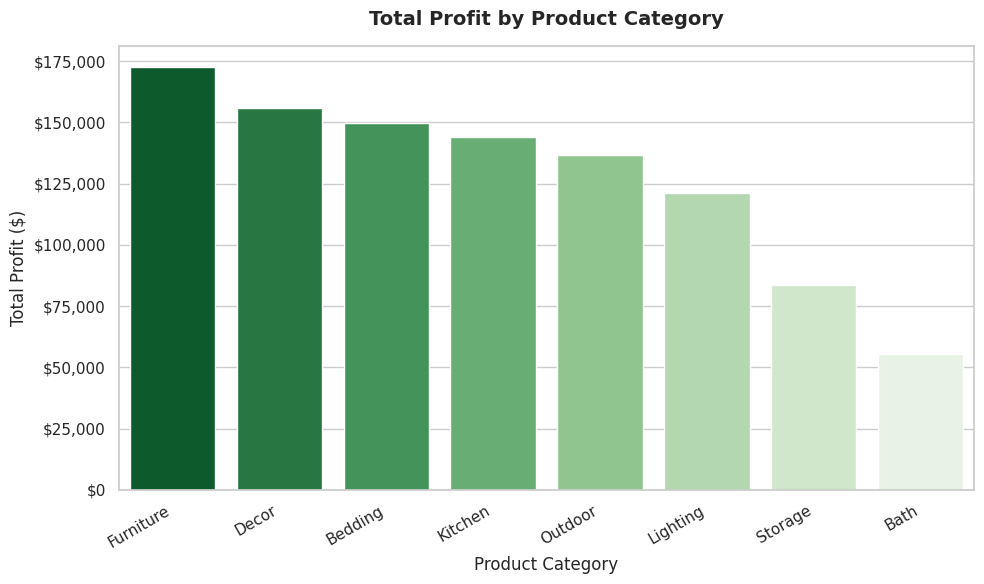

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sort category profit data from highest to lowest total profit
category_profit_sorted = category_profit.sort_values(by='total_profit', ascending=False)

# 2. Set up the figure size and style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Create a clean bar chart
ax = sns.barplot(
    data=category_profit_sorted,
    x='category_new',
    y='total_profit',
    palette='Greens_r'
)

# 4. Add titles, labels, and format y-axis
plt.title('Total Profit by Product Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Profit ($)', fontsize=12)
ax.yaxis.set_major_formatter('${x:,.0f}')

# Rotate x-axis labels for readability
plt.xticks(rotation=30, ha='right')

# 5. Display the chart
plt.tight_layout()
plt.show()

**observation**

**Furniture** is the Profit King: Even though Furniture has the lowest total units sold (1,045 units), it brings in the highest actual dollar profit ($172,654.41) because the items have high price tags.   

**Storage** Has the Highest Margin: While Storage isn't the highest overall profit earner, it boasts the highest profit margin percentage at 55.58%, meaning we keep over 55 cents of every dollar it makes.  

 **Kitchen** Moves the Most Volume: Kitchen sells the highest number of units (4,006 units) and brings in solid profit, showing it's a great workhorse category for driving consistent customer traffic.   

. **Return & Cancellation Cost Analysis (Store Operations)**

In [ ]:
lost_sales = complete_business_data[complete_business_data['status'].isin(['canceled', 'returned'])]
print(lost_sales)

       order_id  product_id  quantity  unit_price_new  discount_amount  \
10       100007        1003         1           22.99             0.00   
11       100007        1039         1          483.99             0.00   
12       100007        1074         1           19.99             0.00   
34       100021        1046         1          142.99             0.00   
35       100021        1033         1           85.99             0.00   
...         ...         ...       ...             ...              ...   
15510    109141        1080         1          141.74             0.00   
15524    109150        1002         1          145.94             0.00   
15525    109150        1007         1           75.59             0.00   
15546    109163        1008         1           46.19             9.24   
15555    109172        1070         3          129.14            77.48   

                  product_name category_new  list_price  unit_cost  \
10      Matte Black Dutch Oven      Kitch

In [ ]:
status_impact = lost_sales.groupby('status').agg(
    order_count=('order_id', 'count'),
    lost_revenue=('total_revenue', 'sum'),
    lost_profit=('total_profit', 'sum')
).reset_index()
print(status_impact)

     status  order_count  lost_revenue  lost_profit
0  canceled          559      75865.48     36897.05
1  returned          766     116856.02     57751.69


In [ ]:
category_lost_profit = lost_sales.groupby('category_new').agg(
    lost_orders=('order_id', 'count'),
    lost_revenue=('total_revenue', 'sum'),
    lost_profit=('total_profit', 'sum')
).reset_index().sort_values(by='lost_profit', ascending=False)
print(category_lost_profit)

  category_new  lost_orders  lost_revenue  lost_profit
3    Furniture          154      50346.96     23673.84
2        Decor          252      26324.01     13555.33
1      Bedding          160      25851.95     13244.73
6      Outdoor          125      26535.16     13237.66
4      Kitchen          258      25456.65     11938.22
5     Lighting           87      17374.00      8185.71
7      Storage          137      11005.85      6123.67
0         Bath          152       9826.92      4689.58


In [ ]:
category_lost_profit.sort_values(by='lost_profit', ascending=False)
print(category_lost_profit)

  category_new  lost_orders  lost_revenue  lost_profit
3    Furniture          154      50346.96     23673.84
2        Decor          252      26324.01     13555.33
1      Bedding          160      25851.95     13244.73
6      Outdoor          125      26535.16     13237.66
4      Kitchen          258      25456.65     11938.22
5     Lighting           87      17374.00      8185.71
7      Storage          137      11005.85      6123.67
0         Bath          152       9826.92      4689.58


In [ ]:
# Group by category and product name to find the biggest culprits
top_problem_products = lost_sales.groupby(['category_new', 'product_name']).agg(
    lost_orders=('order_id', 'count'),
    lost_profit=('total_profit', 'sum')
).reset_index().sort_values(by='lost_profit', ascending=False)

print("--- TOP PROBLEM PRODUCTS BY LOST PROFIT ---")
print(top_problem_products.head(10))

--- TOP PROBLEM PRODUCTS BY LOST PROFIT ---
   category_new               product_name  lost_orders  lost_profit
35    Furniture  Classic Dining Chair Pair           12      3903.54
42    Furniture          Nordic Side Table           12      3692.63
76      Outdoor         Cotton Patio Chair           14      3461.05
39    Furniture           Marble Bookshelf           14      2815.86
77      Outdoor        Matte Black Hammock           11      2552.34
23        Decor            Classic Garland           27      2509.17
33        Decor      Stoneware Wall Mirror           22      2372.17
41    Furniture        Nordic Coffee Table           11      2217.82
25        Decor  Coastal Picture Frame Set           24      2197.29
15      Bedding     Cotton Linen Sheet Set           19      2130.29


**observation**

**Returns cost more than just a lost sale:** When an item is returned or canceled, you don't just lose the revenue—you also eat the cost of reverse shipping, warehouse restocking, and sometimes damaged goods that can't be resold. It’s an active drain on your budget.

**Furniture** is bleeding heavy cash: Because furniture pieces are high-ticket items, even a relatively small number of returns or cancellations wipes out thousands of dollars in profit instantly. Finding out if they are arriving damaged or failing to match customer expectations will plug a massive financial leak.

  **Kitchen** and Decor have a repeating friction problem: Having hundreds of canceled or returned orders in these categories points to a systemic issue. It usually means something is wrong on the website—like misleading product descriptions, poor quality photos, or fulfillment delays that make shoppers change their mind before it even arrives.  

**Bulky, High-Ticket Items Drive Cash Losses**: Furniture and outdoor pieces like the Classic Dining Chair Pair and Cotton Patio Chair top the list because just 11 to 14 canceled or returned orders instantly wipe out $3,400 to $3,900 each.   

**High-Volume Friction in Decor:** Items like the Classic Garland (27 lost orders) and Stoneware Wall Mirror (22 lost orders) suffer from high-frequency returns or cancellations. For fragile or seasonal items like mirrors and garlands, this usually points to shipping breakages or online photos that don't quite match reality.

**The Action Plan for Operations: **Instead of guessing, operations now has an exact hit-list. They need to check shipping and packaging quality for fragile decor and heavy furniture, and review web descriptions and dimensions to ensure customer expectations match what actually arrives.

. Shipping Fee Impact
Analysis (Store Operations):

In [ ]:
# 1. Create a column to flag whether an order had a shipping fee
complete_business_data['has_shipping_fee'] = complete_business_data['shipping_fee'] > 0

# 2. Group by shipping fee status to analyze order value and quantity
shipping_impact = complete_business_data.groupby('has_shipping_fee').agg(
    total_orders=('order_id', 'count'),
    avg_order_value=('total_revenue', 'mean'),
    avg_quantity=('quantity', 'mean'),
    total_revenue=('total_revenue', 'sum')
).reset_index()

# Clean up the boolean label for readability
shipping_impact['shipping_status'] = shipping_impact['has_shipping_fee'].map({True: 'Paid Shipping', False: 'Free Shipping'})

print("--- SHIPPING FEE IMPACT ANALYSIS ---")
print(shipping_impact[['shipping_status', 'total_orders', 'avg_order_value', 'avg_quantity', 'total_revenue']])

--- SHIPPING FEE IMPACT ANALYSIS ---
  shipping_status  total_orders  avg_order_value  avg_quantity  total_revenue
0   Free Shipping         13436       147.715022      1.268086     1984699.04
1   Paid Shipping          2172        41.113048      1.100829       89297.54


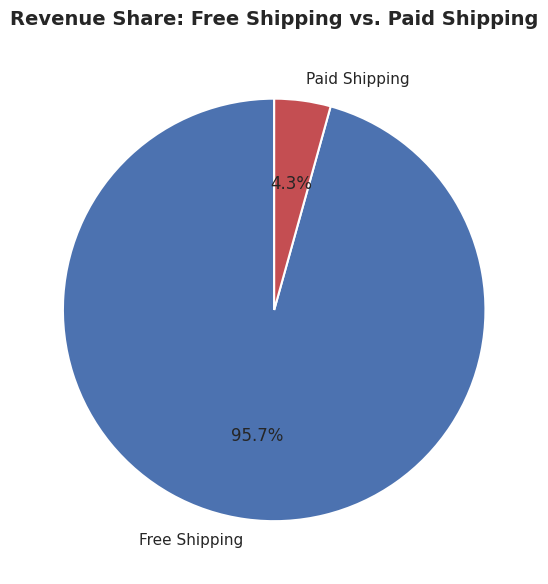

In [ ]:
import matplotlib.pyplot as plt

# 1. Set up figure size
plt.figure(figsize=(8, 6))

# 2. Define data and colors
revenues = shipping_impact['total_revenue']
labels = shipping_impact['shipping_status']
colors = ['#4c72b0', '#c44e52'] # Distinct colors for Free vs Paid

# 3. Create a clean pie chart with percentages
plt.pie(
    revenues,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

# 4. Add title
plt.title('Revenue Share: Free Shipping vs. Paid Shipping', fontsize=14, fontweight='bold', pad=15)

# 5. Display the chart
plt.tight_layout()
plt.show()

**OBSERVATION**

**Free Shipping Dominates Volume & Value:** The vast majority of customers (13,436 orders) opt for free shipping, generating nearly $1.98 million in total revenue with a high average order value of $147.72.  

 **Paid Shipping is a Tiny Fraction: **Only 2,172 orders have paid shipping fees, accounting for just $89,297.54 in total revenue and a much lower average order value of $41.11.

   **Larger Baskets with Free Shipping:** Customers ordering with free shipping buy slightly more items on average (1.27 items) compared to those paying for shipping (1.10 items).  

  **The Bottom Line:** Free shipping is a major catalyst for customer spending and basket size. Rather than deterring sales, offering free shipping successfully encourages customers to check out with much larger, higher-value carts.   

Customer Time-to-First-Order (Customer Timing): Measure the duration between a customer's signup_date and their very first purchase date to evaluate onboarding and welcome email efficiency.



In [ ]:
# 1. Convert date columns to datetime format
complete_business_data['signup_date'] = pd.to_datetime(complete_business_data['signup_date'])
complete_business_data['order_date'] = pd.to_datetime(complete_business_data['order_date'])

# 2. Get the first order date for each customer
first_orders = complete_business_data.groupby('customer_id').agg(
    signup_date=('signup_date', 'first'),
    first_order_date=('order_date', 'min')
).reset_index()

# 3. Calculate days to first order
first_orders['days_to_first_order'] = (first_orders['first_order_date'] - first_orders['signup_date']).dt.days

# 4. Summary metrics
print("--- CUSTOMER TIME-TO-FIRST-ORDER METRICS ---")
print(f"Average Days to First Order: {first_orders['days_to_first_order'].mean():.1f} days")
print(f"Median Days to First Order:  {first_orders['days_to_first_order'].median():.1f} days")

# 5. Group into timing buckets
def timing_bucket(days):
    if days == 0:
        return 'Same Day'
    elif days <= 7:
        return '1 - 7 Days'
    elif days <= 30:
        return '8 - 30 Days'
    else:
        return '30+ Days'

first_orders['timing_bucket'] = first_orders['days_to_first_order'].apply(timing_bucket)
bucket_counts = first_orders['timing_bucket'].value_counts().reindex(['Same Day', '1 - 7 Days', '8 - 30 Days', '30+ Days']).reset_index()
bucket_counts.columns = ['timing_bucket', 'customer_count']

print("\n--- CONVERSION TIMING BUCKETS ---")
print(bucket_counts)

ValueError: time data "13/01/2024" doesn't match format "%m/%d/%Y", at position 12. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [ ]:
# 1. Convert date columns to datetime format safely handling day-first dates
complete_business_data['signup_date'] = pd.to_datetime(complete_business_data['signup_date'], format='mixed', dayfirst=True)
complete_business_data['order_date'] = pd.to_datetime(complete_business_data['order_date'], format='mixed', dayfirst=True)

# 2. Get the first order date for each customer
first_orders = complete_business_data.groupby('customer_id').agg(
    signup_date=('signup_date', 'first'),
    first_order_date=('order_date', 'min')
).reset_index()

# 3. Calculate days to first order
first_orders['days_to_first_order'] = (first_orders['first_order_date'] - first_orders['signup_date']).dt.days

# 4. Summary metrics
print("--- CUSTOMER TIME-TO-FIRST-ORDER METRICS ---")
print(f"Average Days to First Order: {first_orders['days_to_first_order'].mean():.1f} days")
print(f"Median Days to First Order:  {first_orders['days_to_first_order'].median():.1f} days")

# 5. Group into timing buckets
def timing_bucket(days):
    if days == 0:
        return 'Same Day'
    elif days <= 7:
        return '1 - 7 Days'
    elif days <= 30:
        return '8 - 30 Days'
    else:
        return '30+ Days'

first_orders['timing_bucket'] = first_orders['days_to_first_order'].apply(timing_bucket)
bucket_counts = first_orders['timing_bucket'].value_counts().reindex(['Same Day', '1 - 7 Days', '8 - 30 Days', '30+ Days']).reset_index()
bucket_counts.columns = ['timing_bucket', 'customer_count']

print("\n--- CONVERSION TIMING BUCKETS ---")
print(bucket_counts)

--- CUSTOMER TIME-TO-FIRST-ORDER METRICS ---
Average Days to First Order: 62.7 days
Median Days to First Order:  38.0 days

--- CONVERSION TIMING BUCKETS ---
  timing_bucket  customer_count
0      Same Day              47
1    1 - 7 Days             253
2   8 - 30 Days             628
3      30+ Days            1178


**OBSERVATION**

**The Long Wait**: The average customer takes 62.7 days (and a median of 38 days) just to make their very first purchase after signing up.   The


**Drop-Off in Urgency**: Out of all the timing buckets, the massive 30+ Days category is by far the largest, holding 1,178 customers who wait over a month before buying.  

 **The Bottom Line**: Signups are going cold instead of converting quickly. This means the current onboarding and welcome email sequence isn't creating immediate urgency—highlighting a prime opportunity to introduce time-sensitive sign-up discounts or more engaging welcome campaigns right after registration.

Executive **Insights** & Operational LeaksMarketing & Acquisition:


1.Organic Search drives the bulk of your customer volume.

Paid Search and Referrals bring in fewer customers overall, but those customers place significantly larger orders.   

2.Pricing & Discount Strategy:Flat-rate discount codes fail to increase basket size—average order quantity stays stuck around 1.24 items.  

 Instead of driving higher sales volume, discounts are simply eroding profit margins on purchases customers would have made anyway

 3.Category Profitability & Volume:Furniture is your highest dollar-profit generator despite selling fewer units (1,045 units), thanks to high individual price tags.   Storage delivers your most efficient returns with the highest profit margin (55.58%).

   Kitchen is your volume workhorse (4,006 units sold), consistently drawing shoppers in.   

4.Shipping & Cart Value:Free Shipping is your single largest revenue engine, driving $1.98M in sales across 13,436 orders with a much higher average order value ($147.72) compared to paid shipping ($41.11).   

5.Customer Conversion Timing:Customers take an average of 62.7 days (median 38 days) between signing up and placing their first order, with 1,178 signups waiting over a month.   The current onboarding journey allows leads to grow cold instead of driving immediate purchases.   



**Strategic Recommendations**

1. Overhaul the Onboarding Sequence:

Deploy time-sensitive welcome offers (e.g., 10% off valid for the first 48 hours) to convert new signups immediately rather than waiting 30+ days

2.Fix Product & Shipping Expectations for High-Loss Items:Audit packaging and delivery partners for heavy items (Classic Dining Chair, Patio Chair) to stop $3,000+ return hits.   Upgrade website imagery and dimensions for decor/mirror items to eliminate customer disappointment upon delivery.   

3.Transition from Flat Discounts to Spend Thresholds:Replace general flat-rate coupon codes with tiered thresholds (e.g., "Spend $150 to get $20 off") to force basket sizes past the current 1.24-item plateau.   

4.Capitalize on Free Shipping:Maintain free shipping as a core acquisition driver, but pair it with a minimum cart threshold to protect margins while encouraging multi-item orders.   